# ¿Qué nos cuentan las medidas de los pingüinos?
**Analítica de datos · Universidad Católica de Pereira**  
Andrés Felipe Torres Cano

Una tabla de medidas puede parecer una colección de números aislados. Sin embargo, al observarla con cuidado aparecen diferencias, relaciones y nuevas preguntas. En este recorrido investigaremos cómo cambia la masa corporal entre especies de pingüinos y qué relación tiene con la longitud de sus aletas.

Comenzaremos con los registros originales, revisaremos qué información falta y construiremos una base adecuada para nuestra pregunta. Después usaremos seaborn para pasar de los números a patrones visibles, y de esos patrones a conclusiones respaldadas por evidencia.

Las celdas se ejecutan en orden con **Shift + Enter**. En Jupyter, `penguins.csv` debe estar junto al cuaderno; en Colab se puede subir al panel Archivos. Si no está disponible localmente, el código descargará la copia pública. Los gráficos y las tablas ya están guardados para facilitar la lectura.

Primero preparamos las herramientas: pandas para trabajar con tablas, seaborn para explorar visualmente y matplotlib para ajustar y guardar las figuras.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["figure.dpi"] = 110
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| seaborn:", sns.__version__, "| matplotlib:", matplotlib.__version__)

Python: 3.12.14
pandas: 3.1.0 | seaborn: 0.13.2 | matplotlib: 3.11.2


## Empezar por una pregunta
Nuestro objetivo es comprender las diferencias de masa entre especies. Para responder, necesitamos conocer qué representa cada registro, comprobar la calidad de las medidas y distinguir los patrones generales de los que aparecen dentro de cada grupo.

La pregunta que guiará el análisis es: **¿cómo cambia la masa corporal entre especies y cómo se relaciona con la longitud de la aleta?** Cada fila corresponde a un pingüino observado. No bastará con comparar promedios: también necesitaremos saber cuántas observaciones tenemos y cuánto varían las medidas dentro de cada especie.

## Conocer a los protagonistas
Trabajaremos con Palmer Penguins, datos recopilados por Kristen Gorman y Palmer Station LTER en el archipiélago Palmer, en la Antártida. La versión de seaborn contiene 344 registros y siete variables: especie, isla, sexo y cuatro medidas corporales.

Estos registros permiten explorar una muestra concreta. Las conclusiones que obtengamos tendrán ese alcance; no describirán automáticamente a todos los pingüinos del mundo.

### Abrir los datos
Leemos la copia local cuando está disponible y conservamos una copia intacta. Las primeras filas permiten reconocer la estructura; el tamaño de la tabla y los tipos de columnas nos ayudan a comprobar qué recibimos antes de transformarlo.

In [2]:
# La copia local fija la misma versión de datos de la presentación.
ruta = Path("penguins.csv")
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
if ruta.exists():
    df = pd.read_csv(ruta)
    print("Fuente: copia local", ruta)
else:
    df = pd.read_csv(url)
    print("Fuente: repositorio público de seaborn")
base_original = df.copy(deep=True)
display(df.head())
print("Filas y columnas:", df.shape)
df.info()

Fuente: copia local penguins.csv


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Filas y columnas: (344, 7)
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


### Dar significado a las columnas
Las unidades son parte del dato: una longitud en milímetros y una masa en gramos no se interpretan de la misma manera.

| Variable | Qué representa |
| --- | --- |
| `species`, `island`, `sex` | Especie, isla y sexo |
| `bill_length_mm`, `bill_depth_mm` | Longitud y profundidad del pico, en milímetros |
| `flipper_length_mm` | Longitud de la aleta, en milímetros |
| `body_mass_g` | Masa corporal, en gramos |

Con este diccionario podemos distinguir categorías de medidas numéricas y seleccionar las variables necesarias para nuestra pregunta.

## Antes de comparar, revisar la calidad
Una tabla puede tener suficientes filas y aun así estar incompleta. Contaremos los valores ausentes, buscaremos filas idénticas y revisaremos los resúmenes de las columnas. Este diagnóstico permite decidir qué cambios son necesarios sin alterar los datos por costumbre.

In [3]:
calidad = pd.DataFrame({"tipo": df.dtypes.astype(str), "faltantes": df.isna().sum(),
                        "porcentaje_faltante": df.isna().mean().mul(100)})
display(calidad.round(2))
print("Filas completamente duplicadas:", df.duplicated().sum())
display(df.describe(include="all").T)
display(df["species"].value_counts(dropna=False))

,tipo,faltantes,porcentaje_faltante
species,str,0,0.00
island,str,0,0.00
bill_length_mm,float64,2,0.58
bill_depth_mm,float64,2,0.58
flipper_length_mm,float64,2,0.58
body_mass_g,float64,2,0.58
sex,str,11,3.20


Filas completamente duplicadas: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
species,344,3,Adelie,152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
island,344,3,Biscoe,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bill_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
bill_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,200.915205,14.061714,172.0,190.0,197.0,213.0,231.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,333,2,MALE,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

### Lo que falta también cuenta
Encontramos dos valores ausentes en cada medida numérica y once en sexo. No hay filas completamente duplicadas, aunque esto no demuestra que todos los individuos sean únicos: la tabla no incluye un identificador que permita comprobarlo.

Eliminar toda fila incompleta haría perder información útil para preguntas que no utilizan sexo. Imputar también exige un supuesto; rellenar la masa con cero introduciría una medida artificial. Antes de decidir, examinamos cómo se distribuyen los faltantes entre especies.

El siguiente resumen compara la cantidad de registros sin sexo y su proporción dentro de cada especie.

In [4]:
faltantes_grupo = df.assign(sexo_faltante=df["sex"].isna()).groupby("species").agg(
    registros=("species", "size"), sin_sexo=("sexo_faltante", "sum"))
faltantes_grupo["porcentaje_sin_sexo"] = 100 * faltantes_grupo["sin_sexo"] / faltantes_grupo["registros"]
display(faltantes_grupo.round(2))

,registros,sin_sexo,porcentaje_sin_sexo
species,,,
Adelie,152,6,3.95
Chinstrap,68,0,0.00
Gentoo,124,5,4.03


Cada porcentaje usa como denominador el número de filas de su especie. La ausencia de sexo será relevante cuando comparemos ese atributo, pero no impide analizar una masa y una aleta que sí fueron medidas.

### Preparar solo lo necesario
Para estudiar masa y aleta exigimos valores observados en esas variables y en especie. Esta decisión conserva 342 registros. Mantenemos las filas sin sexo porque todavía pueden aportar evidencia a la pregunta principal.

Además, expresamos la masa en kilogramos para mostrar una transformación de unidades. `masa_kg` contiene la misma información que `body_mass_g`, dividida por mil.

In [5]:
base = df.copy()
eda = base.dropna(subset=[
    "species", "body_mass_g",
    "flipper_length_mm"
]).copy()

eda["masa_kg"] = (
    eda["body_mass_g"] / 1000
)
len(base), len(eda)
print(f"Antes: {len(base)}; después: {len(eda)}; excluidas: {len(base)-len(eda)}")
display(eda[["body_mass_g", "masa_kg"]].head())

Antes: 344; después: 342; excluidas: 2


,body_mass_g,masa_kg
0,3750.0,3.75
1,3800.0,3.80
2,3250.0,3.25
4,3450.0,3.45
5,3650.0,3.65


### Un extremo no es necesariamente un error
Una masa muy alta o muy baja puede deberse a una diferencia real, a un problema de registro o a la pertenencia a otro grupo. Usaremos una regla estadística para localizar valores que merecen revisión, sin eliminarlos automáticamente.

El rango intercuartílico es **IQR = Q3 − Q1**. Marcamos valores inferiores a Q1 − 1,5 × IQR o superiores a Q3 + 1,5 × IQR. Calculamos esos límites por especie para evitar confundir diferencias entre especies con anomalías individuales.

La siguiente celda identifica candidatos y conserva todas las observaciones en la base de análisis.

In [6]:
grupo = eda.groupby("species")["body_mass_g"]
q1 = grupo.transform(lambda s: s.quantile(0.25))
q3 = grupo.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
candidatos = eda.loc[(eda["body_mass_g"] < q1 - 1.5 * iqr) |
                     (eda["body_mass_g"] > q3 + 1.5 * iqr)]
display(candidatos[["species", "body_mass_g", "flipper_length_mm"]])
print("Candidatos a revisión:", len(candidatos), "(no se eliminan)")

,species,body_mass_g,flipper_length_mm
189,Chinstrap,4800.0,210.0
190,Chinstrap,2700.0,192.0


Candidatos a revisión: 2 (no se eliminan)


Los candidatos son señales para investigar. Antes de descartarlos necesitaríamos revisar las unidades, el registro original y las condiciones de medición. La regla por sí sola no demuestra que haya un error.

## La primera pista aparece al agrupar
Ya podemos resumir la masa por especie. El conteo muestra cuánta evidencia tenemos, la mediana describe el centro y la media permite observar otra medida de tendencia central. Compararlas es un primer paso; todavía falta ver la distribución completa.

In [7]:
resumen = eda.groupby("species")[
    "body_mass_g"
].agg(["count", "median", "mean"])

display(resumen.round(1))

,count,median,mean
species,,,
Adelie,151,3700.0,3700.7
Chinstrap,68,3700.0,3733.1
Gentoo,123,5000.0,5076.0


### Elegir una vista para cada pregunta
Gentoo presenta una mediana de masa mayor, mientras que Adelie y Chinstrap comparten una mediana de 3700 g. Para entender qué hay detrás de esos números, necesitamos varias vistas de los mismos datos.

| Lo que queremos entender | Herramientas de seaborn |
| --- | --- |
| La distribución de una medida | `histplot`, `ecdfplot` |
| La cantidad de registros por categoría | `countplot` |
| Las diferencias de distribución entre grupos | `boxplot`, `stripplot` |
| La relación entre dos medidas | `scatterplot`, `regplot` |
| Las relaciones al separar grupos | `relplot`, `pairplot` |

Cada gráfico responderá una parte de la pregunta.

## Ver la distribución antes de reducirla a un número
El histograma reúne las masas en intervalos y cuenta cuántas observaciones caen en cada uno. Nos permite reconocer el rango, las zonas donde se concentran los registros y posibles cambios en la forma de la distribución.

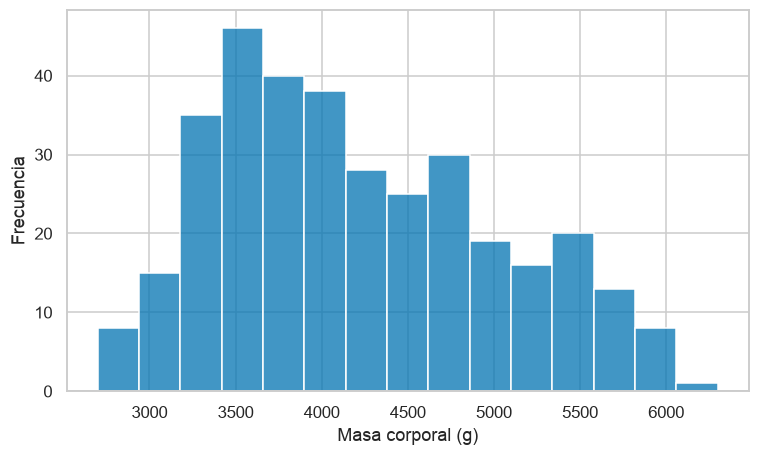

In [8]:
sns.histplot(
    data=eda, x="body_mass_g",
    bins=15
)
plt.xlabel("Masa corporal (g)")
plt.ylabel("Frecuencia")
plt.show()

En el código, `data` indica la tabla, `x` selecciona la medida y `bins` fija la cantidad de intervalos. `plt.show()` muestra la figura. La imagen resume las masas de todas las especies juntas.

### ¿Cuánto depende la imagen de los intervalos?
La forma de un histograma depende de cómo agrupemos los valores. Repetimos la vista con intervalos de 250 g para comprobar qué rasgos se mantienen al cambiar esa elección.

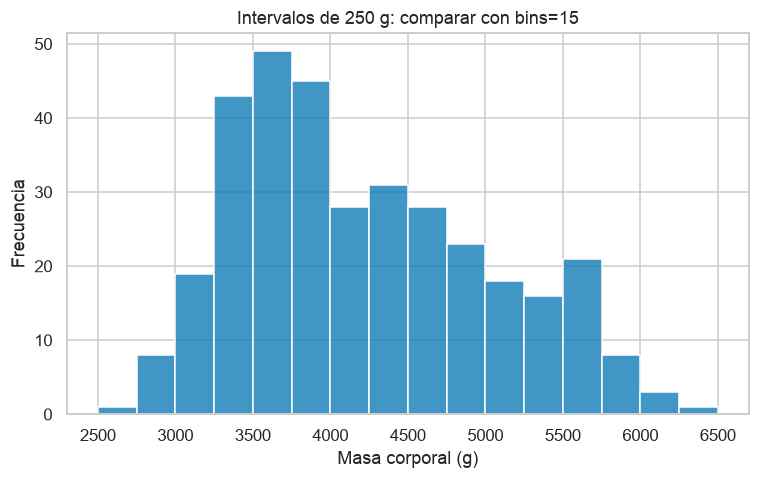

In [9]:
intervalos = np.arange(2500, 6501, 250)
sns.histplot(data=eda, x="body_mass_g", bins=intervalos)
plt.xlabel("Masa corporal (g)")
plt.ylabel("Frecuencia")
plt.title("Intervalos de 250 g: comparar con bins=15")
plt.show()

Las 342 masas combinan especies con tamaños diferentes. Las concentraciones visibles son pistas que debemos contrastar separando grupos; un pico no demuestra por sí solo la existencia de una población distinta.

### Comparar sin escoger intervalos
La distribución acumulada empírica, o ECDF, muestra qué proporción de cada especie tiene una masa menor o igual a un valor. Una altura de 0,5 corresponde aproximadamente a la mediana. Al separar por especie podemos comparar sus posiciones sin elegir intervalos ni un suavizado.

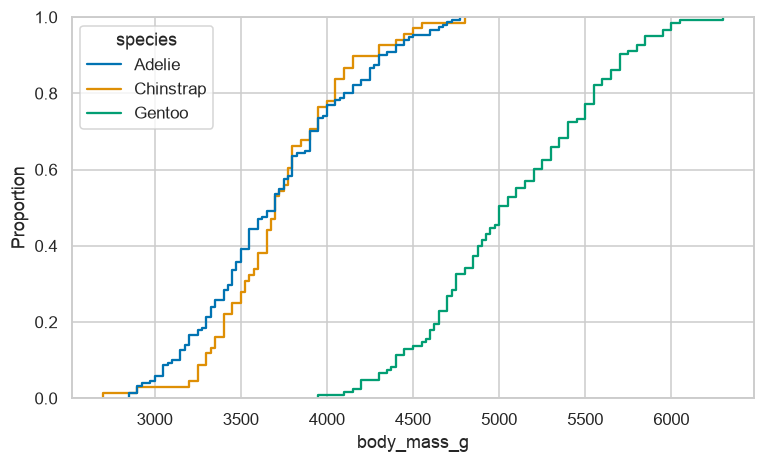

In [10]:
sns.ecdfplot(
    data=eda, x="body_mass_g",
    hue="species"
)
plt.show()

## No todas las especies aportan la misma cantidad de datos
Antes de comparar distribuciones conviene conocer la composición de la muestra. `countplot` cuenta registros por categoría; las proporciones expresan esos conteos respecto al total. Aquí usamos la tabla original porque contar especies no exige tener todas las medidas corporales.

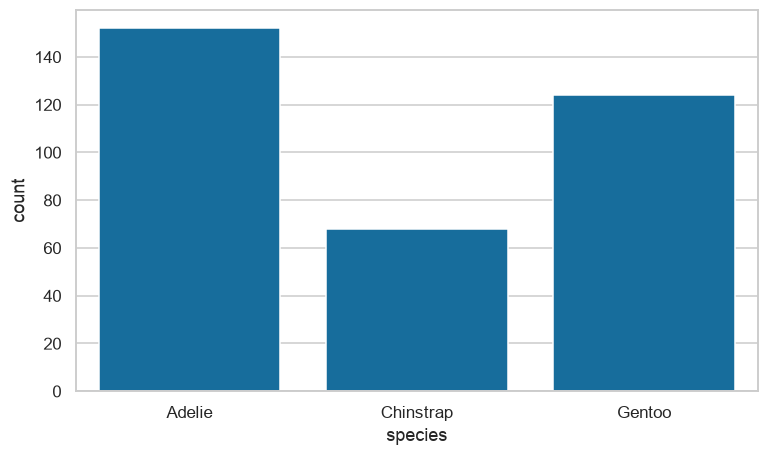

species
Adelie       0.441860
Gentoo       0.360465
Chinstrap    0.197674
Name: proporcion, dtype: float64

In [12]:
sns.countplot(
    data=df, x="species"
)
plt.show()

display(df["species"].value_counts(normalize=True).rename("proporcion"))

Adelie es la especie más frecuente en esta muestra. Estos conteos no describen la abundancia mundial de las especies. También explican por qué el histograma agregado da más peso a unos grupos que a otros.

In [13]:
display(df["species"].value_counts().rename("registros").to_frame())

,registros
species,
Adelie,152
Gentoo,124
Chinstrap,68


## Comparar las masas dentro de cada especie
El boxplot resume cada distribución: la caja contiene el 50 % central de las observaciones y la línea interior marca la mediana. Los bigotes llegan hasta los valores observados dentro de los límites de 1,5 × IQR; no representan necesariamente el mínimo y máximo de todo el grupo.

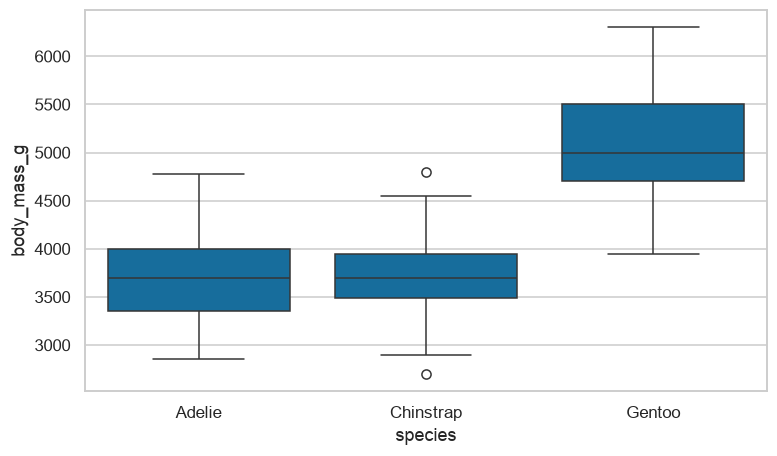

In [14]:
sns.boxplot(
    data=eda, x="species",
    y="body_mass_g"
)
plt.show()

### Una mediana compartida no implica distribuciones iguales
Adelie y Chinstrap tienen la misma mediana, pero esa coincidencia no resume toda su variación. Las cajas, los bigotes y los puntos exteriores permiten comparar la dispersión además del centro.

Gentoo ocupa valores de masa generalmente mayores. Los puntos que quedan fuera de los bigotes siguen siendo observaciones que debemos comprender; no desaparecen del análisis por resultar extremos.

### Volver a las observaciones individuales
Ahora mostramos cada registro como un punto. Esta vista conecta los resúmenes anteriores con los datos que los originan.

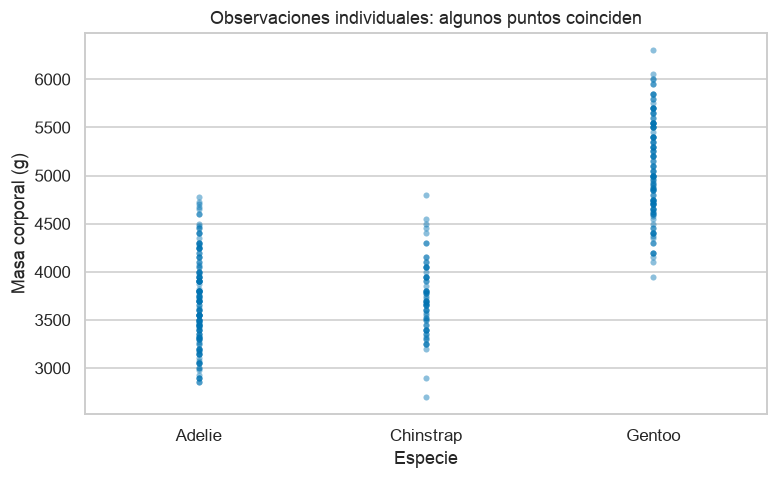

In [16]:
sns.stripplot(data=eda, x="species", y="body_mass_g", jitter=False, alpha=0.45, size=4)
plt.xlabel("Especie")
plt.ylabel("Masa corporal (g)")
plt.title("Observaciones individuales: algunos puntos coinciden")
plt.show()

Al no desplazar horizontalmente los puntos, algunas observaciones coinciden y se tapan. `jitter=True` permite separarlas ligeramente; ese desplazamiento solo facilita la lectura y no representa una nueva variable. Para muestras pequeñas, `swarmplot` ofrece otra forma de reducir la superposición.

## ¿Una aleta más larga acompaña una masa mayor?
Hasta ahora hemos comparado una medida entre especies. El gráfico de dispersión incorpora una segunda: cada punto combina la longitud de la aleta y la masa de un pingüino. Color y símbolo identifican la especie para distinguir grupos sin depender únicamente del color.

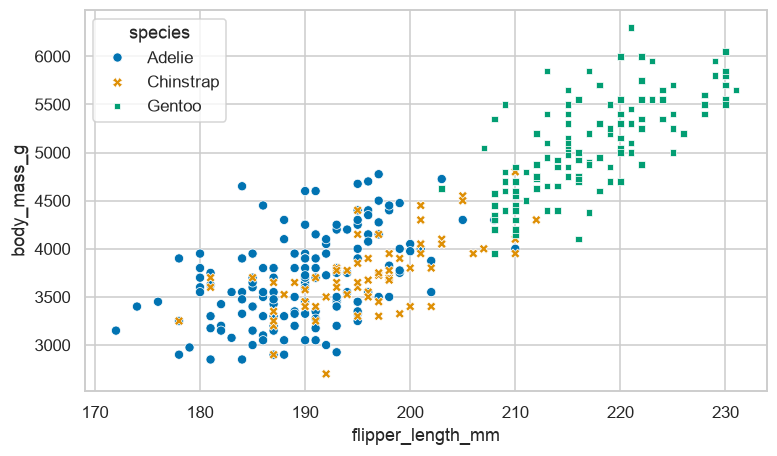

In [17]:
sns.scatterplot(
    data=eda,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species", style="species"
)
plt.show()

`hue` y `style` representan la misma categoría mediante color y símbolo. Esta separación permite reconocer tanto las diferencias entre especies como la variación entre individuos de una misma especie.

### Separar una tendencia global de las tendencias de cada grupo
La nube agregada sugiere una asociación positiva entre aleta y masa. Sin embargo, parte de ese patrón puede reflejar que unas especies tienen aletas y cuerpos mayores que otras. Añadiremos rectas descriptivas para comparar la tendencia conjunta con las tendencias por especie.

Primero ajustamos una recta al conjunto completo y después una por especie.

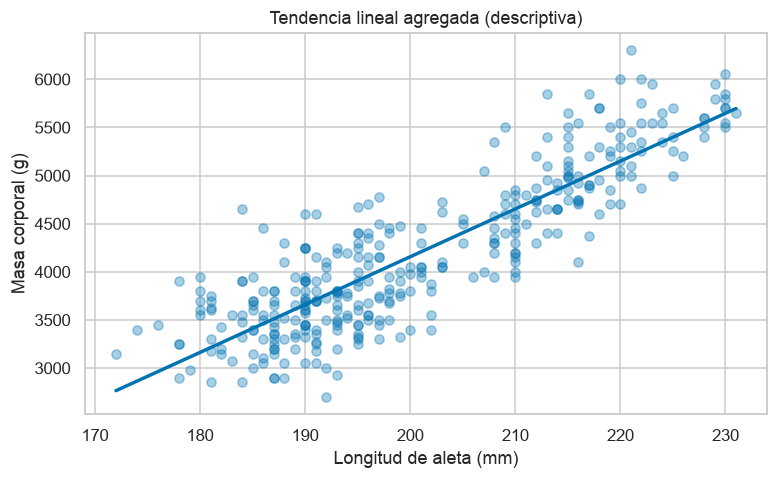

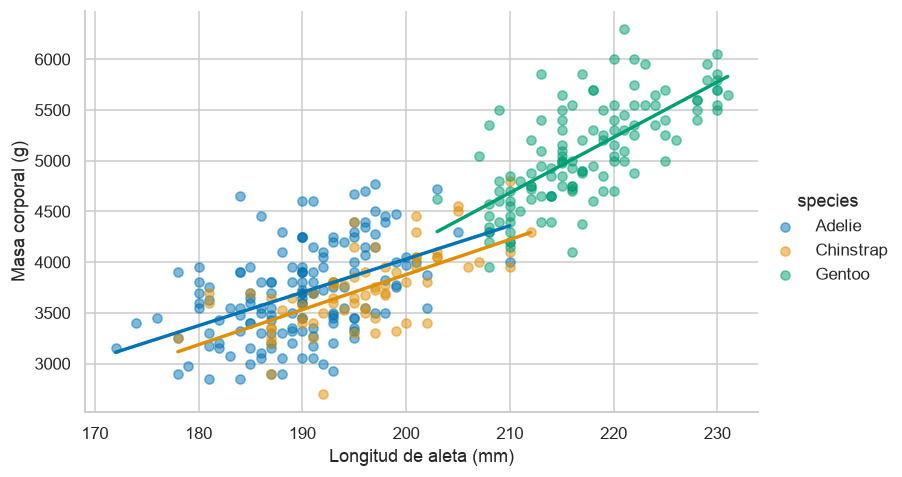

In [18]:
sns.regplot(data=eda, x="flipper_length_mm", y="body_mass_g", ci=None,
            scatter_kws={"alpha": 0.35})
plt.title("Tendencia lineal agregada (descriptiva)")
plt.xlabel("Longitud de aleta (mm)")
plt.ylabel("Masa corporal (g)")
plt.show()
g = sns.lmplot(data=eda, x="flipper_length_mm", y="body_mass_g", hue="species",
               ci=None, height=4.5, aspect=1.6, scatter_kws={"alpha": 0.5})
g.set_axis_labels("Longitud de aleta (mm)", "Masa corporal (g)")
plt.show()

Las rectas resumen asociaciones; no prueban que aumentar la longitud de la aleta cause un aumento de masa. Tampoco evalúan capacidad predictiva: todavía no hemos separado datos de entrenamiento y prueba. La relación agregada mezcla variación dentro de las especies y diferencias entre ellas.

### Abrir una ventana para cada especie
Las facetas permiten observar los grupos por separado con escalas comparables. Incorporamos el sexo para explorar otra posible fuente de variación. Esta vez excluimos explícitamente las filas sin ese dato y mostramos cuántas observaciones quedan.

`relplot` administra su propia figura y organiza los paneles; no necesita recibir un eje con `ax`.

Masa y aleta: 342; también sexo: 333


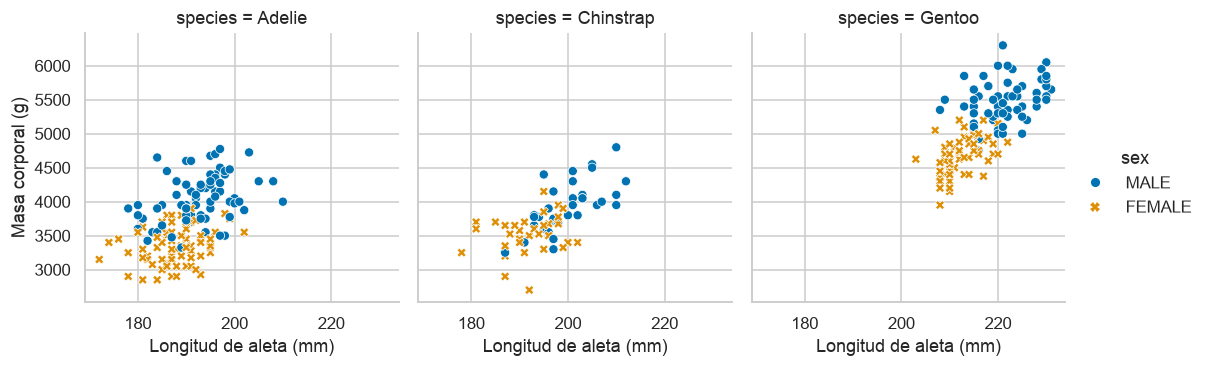

In [19]:
facetas = eda.dropna(subset=["sex"]).copy()
print(f"Masa y aleta: {len(eda)}; también sexo: {len(facetas)}")
g = sns.relplot(data=facetas, x="flipper_length_mm", y="body_mass_g",
                col="species", hue="sex", style="sex", kind="scatter",
                height=3.5, aspect=0.95)
g.set_axis_labels("Longitud de aleta (mm)", "Masa corporal (g)")
plt.show()

## Resumir las relaciones sin perder el contexto
La correlación de Pearson resume la dirección y fuerza de una asociación lineal. Un mapa de calor permite comparar varias parejas de medidas a la vez.

Excluimos `masa_kg` porque duplica la información de `body_mass_g` en otra unidad. Un coeficiente cercano a cero no descarta relaciones no lineales, y un valor alto no demuestra causalidad.

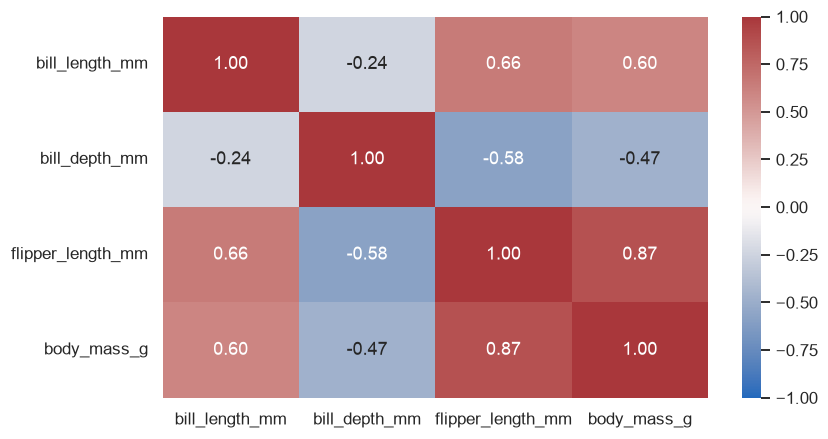

In [20]:
num = eda.select_dtypes("number")
corr = num.drop(columns="masa_kg").corr()
sns.heatmap(
    corr, annot=True, fmt=".2f",
    cmap="vlag", center=0,
    vmin=-1, vmax=1
)
plt.show()

### El mismo coeficiente puede esconder grupos distintos
Cada celda del mapa resume una pareja de variables. Para entender de dónde surge la asociación entre aleta y masa, contrastaremos la correlación global con la calculada dentro de cada especie.

Esta comparación conecta el resumen numérico con los grupos que vimos en el gráfico de dispersión.

In [21]:
global_r = eda["flipper_length_mm"].corr(eda["body_mass_g"])
por_especie = pd.Series({nombre: datos["flipper_length_mm"].corr(datos["body_mass_g"])
                        for nombre, datos in eda.groupby("species")}, name="Pearson")
print(f"Correlación global aleta–masa: {global_r:.3f}")
display(por_especie.round(3))

Correlación global aleta–masa: 0.871


Adelie       0.468
Chinstrap    0.642
Gentoo       0.703
Name: Pearson, dtype: float64

Los coeficientes cambian al separar especies: la composición de la muestra influye en el resumen global. Por eso interpretamos la correlación junto con la dispersión, los grupos y el contexto de recolección.

### Reunir varias relaciones en una sola vista
El pairplot cruza unas pocas variables relevantes y colorea las observaciones por especie. La diagonal muestra distribuciones individuales; las demás celdas muestran relaciones entre pares. Seleccionamos solo tres medidas para mantener una matriz legible.

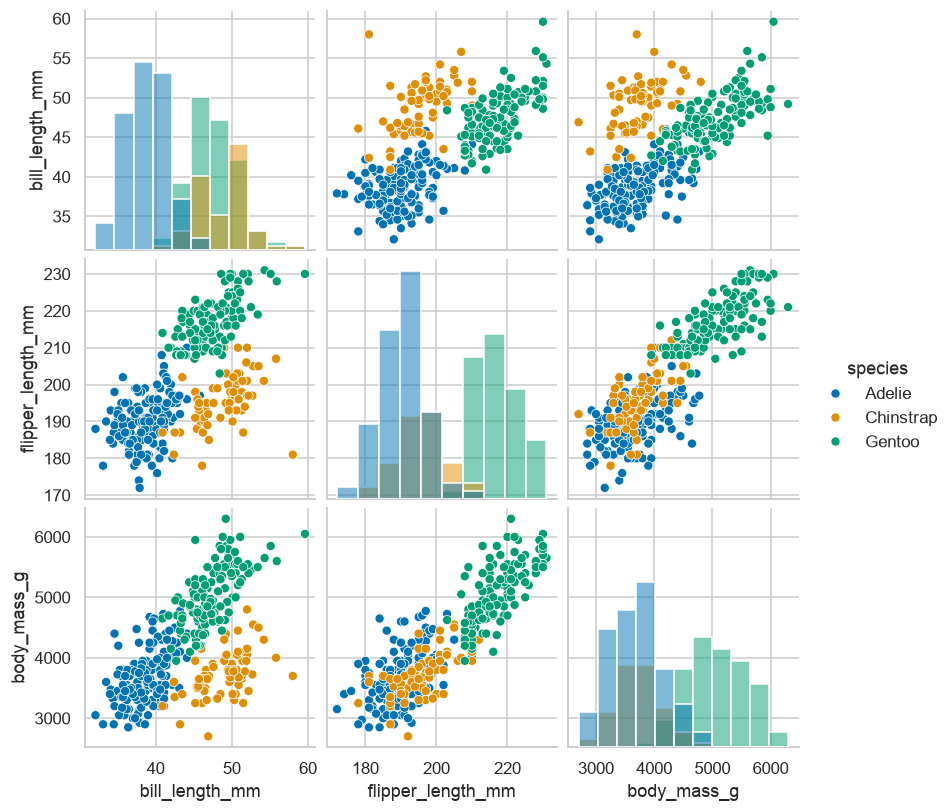

In [22]:
sns.pairplot(
    data=eda,
    vars=["bill_length_mm",
          "flipper_length_mm",
          "body_mass_g"],
    hue="species",
    diag_kind="hist"
)
plt.show()

## Convertir la evidencia en una figura que podamos compartir
Seaborn nos ha permitido expresar las relaciones mediante nombres de columnas y categorías. Matplotlib nos ayuda ahora a ajustar etiquetas, organizar el espacio y guardar una figura con resolución suficiente para reutilizarla.

Retomamos la comparación de masa por especie, escribimos las unidades en el eje y guardamos la imagen. `boxplot` trabaja sobre un eje y acepta `ax`; funciones como `relplot` crean y administran su propia figura.

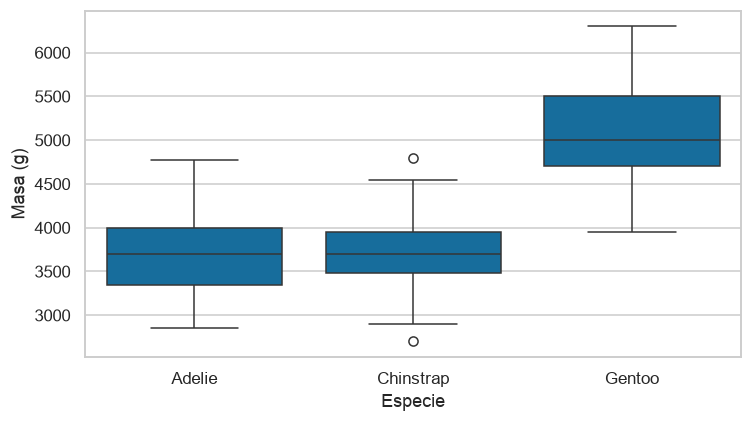

Gráfico guardado en salidas/masa_por_especie.png


In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(
    data=eda, x="species",
    y="body_mass_g", ax=ax
)
ax.set(xlabel="Especie",
       ylabel="Masa (g)")
fig.tight_layout()
Path("salidas").mkdir(exist_ok=True)
fig.savefig("salidas/masa_por_especie.png", dpi=180, bbox_inches="tight")
plt.show()
print("Gráfico guardado en salidas/masa_por_especie.png")

## Volver a la pregunta inicial
La evidencia apunta a una mayor masa corporal en Gentoo dentro de esta muestra. Hemos llegado a esa conclusión comparando centros, distribuciones y conteos, y examinando relaciones entre medidas.

Aun así, una diferencia observada no identifica su causa. Las escalas, las exclusiones y la composición de los grupos forman parte de la interpretación tanto como los gráficos.

Si el siguiente paso fuera construir un modelo predictivo, necesitaríamos reservar datos de prueba antes de explorar relaciones con el objetivo y aprender las transformaciones solo con los datos de entrenamiento. El análisis actual es descriptivo.

### Comprobar el alcance de la conclusión
La mediana de Gentoo es 5000 g, frente a 3700 g en Adelie y Chinstrap, calculadas sobre masas observadas y sin imputación. Antes de atribuir las diferencias a la especie, revisamos también cómo se distribuyen los registros entre islas.

Reunimos el resumen de masas y una tabla que cruza especie con isla.

In [24]:
display(resumen.round(1))
display(pd.crosstab(df["species"], df["island"]))

,count,median,mean
species,,,
Adelie,151,3700.0,3700.7
Chinstrap,68,3700.0,3733.1
Gentoo,123,5000.0,5076.0


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,52
Chinstrap,0,68,0
Gentoo,124,0,0


No todas las especies aparecen en todas las islas. Esa composición dificulta separar el papel de ambas variables. El sexo, la isla y las condiciones de medición siguen siendo parte del contexto que necesitamos para profundizar.

Podemos sostener que Gentoo presenta mayor mediana de masa en esta muestra. No podemos convertir esa observación en una explicación causal ni extrapolarla sin más a otras poblaciones.

## Fuentes para seguir explorando

- [Tutoriales de seaborn](https://seaborn.pydata.org/tutorial.html)
- [Funciones de eje y de figura](https://seaborn.pydata.org/tutorial/function_overview.html)
- [Palmer Penguins: procedencia y contexto](https://allisonhorst.github.io/palmerpenguins/)
- [Datos faltantes en pandas](https://pandas.pydata.org/docs/user_guide/missing_data.html)
- [Copia de los datos utilizada](https://github.com/mwaskom/seaborn-data/blob/master/penguins.csv)

Los datos fueron recopilados por Kristen Gorman y Palmer Station LTER. La copia de seaborn utilizada aquí tiene siete columnas; el conjunto original incluye también el año.

## Dejar un análisis que se pueda reconstruir
Terminamos guardando la base preparada, el resumen por especie y las decisiones de limpieza. Estos archivos conservan la evidencia del recorrido y permiten revisar cómo llegamos a las conclusiones.

La tabla original permanece intacta. Las exclusiones se vinculan con la pregunta, las transformaciones tienen una razón y los valores extremos se conservan para su revisión. Así, el resultado del EDA incluye tanto los hallazgos como un camino reproducible para obtenerlos.

In [25]:
carpeta = Path("salidas")
carpeta.mkdir(exist_ok=True)
eda.to_csv(carpeta / "penguins_eda.csv", index=False)
resumen.to_csv(carpeta / "resumen_masa_especie.csv")
decisiones = pd.DataFrame([
    ["Conservar original", len(df), "Copia intacta para trazabilidad"],
    ["Exigir especie, masa y aleta", len(eda), "Variables necesarias para la pregunta"],
    ["Convertir g a kg", len(eda), "Dividir por 1000, sin cambiar el fenómeno"],
    ["Conservar candidatos IQR", len(eda), "Una señal estadística no demuestra un error"]
], columns=["decision", "filas", "justificacion"])
decisiones.to_csv(carpeta / "decisiones.csv", index=False)
assert df.equals(base_original), "La copia original cambió"
assert len(eda) == 342 and eda["masa_kg"].equals(eda["body_mass_g"] / 1000)
display(decisiones)
print("Listo: salidas disponibles en", carpeta.resolve())

,decision,filas,justificacion
0,Conservar original,344,Copia intacta para trazabilidad
1,"Exigir especie, masa y aleta",342,Variables necesarias para la pregunta
2,Convertir g a kg,342,"Dividir por 1000, sin cambiar el fenómeno"
3,Conservar candidatos IQR,342,Una señal estadística no demuestra un error


Listo: salidas disponibles en /Users/elfotografo007/Documents/UCP/Analítica de Datos/Cuadernos/salidas
